In [ ]:
# =========================
# 1. Import Libraries
# =========================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

In [ ]:

# =========================
# 2. Load Dataset
# =========================

from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv("/content/drive/MyDrive/PS_20174392719_1491204439457_log.csv")

print(df.head())
print(df.shape)
print(df.isnull().sum())

Mounted at /content/drive
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0  
4  M1230701703             0.0             0.0        0               0  
(6362620, 11)
step              0
type              0
amount            0
nameO

In [ ]:
# =========================
# 3. Feature Engineering
# =========================

df["origin_balance_diff"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["dest_balance_diff"] = df["newbalanceDest"] - df["oldbalanceDest"]

df["amount_to_oldbalance_ratio"] = df["amount"] / (df["oldbalanceOrg"] + 1)
df["amount_to_destbalance_ratio"] = df["amount"] / (df["oldbalanceDest"] + 1)

df["is_zero_oldbalanceOrg"] = (df["oldbalanceOrg"] == 0).astype(int)
df["is_zero_newbalanceOrig"] = (df["newbalanceOrig"] == 0).astype(int)
df["is_zero_oldbalanceDest"] = (df["oldbalanceDest"] == 0).astype(int)
df["is_zero_newbalanceDest"] = (df["newbalanceDest"] == 0).astype(int)

In [ ]:
# =========================
# 4. Drop Unnecessary Columns
# =========================

df = df.drop([col for col in ["nameOrig", "nameDest"] if col in df.columns], axis=1)

# Leakage column
df = df.drop([col for col in ["isFlaggedFraud"] if col in df.columns], axis=1)


In [ ]:
# =========================
# 5. One-Hot Encoding
# =========================

if "type" in df.columns:
    df = pd.get_dummies(df, columns=["type"], drop_first=True)

In [ ]:

# =========================
# 6. Split Features and Target
# =========================

X = df.drop("isFraud", axis=1)
y = df["isFraud"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("Normal transactions:", (y == 0).sum())
print("Fraud transactions:", (y == 1).sum())

Features shape: (6362620, 18)
Target shape: (6362620,)
Normal transactions: 6354407
Fraud transactions: 8213


In [ ]:
# =========================
# 7. Train Autoencoder Only on Normal Data
# =========================

X_train = X[y == 0]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

# For evaluation, transform full dataset
X_test_scaled = scaler.transform(X)

In [ ]:
# ========================= # 8. Build Autoencoder Model # =========================
#input_dim = X_train_scaled.shape[1]
#input_layer = Input(shape=(input_dim,))
#Encoder
#encoded = Dense(32, activation="relu")(input_layer)
#encoded = Dense(16, activation="relu")(encoded)
#latent = Dense(8, activation="relu")(encoded)
 # Decoder
#decoded = Dense(16, activation="relu")(latent)
#decoded = Dense(32, activation="relu")(decoded)
#output_layer = Dense(input_dim, activation="linear")(decoded)
#autoencoder = Model(input_layer, output_layer)
#autoencoder.compile( optimizer=Adam(learning_rate=0.001), loss="mse")
#autoencoder.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 18)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 32)             │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 18)             │           594 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,554 (9.98 KB)

 Trainable params: 2,554 (9.98 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.layers import Dropout
from tensorflow.keras.regularizers import l2

input_dim = X_train_scaled.shape[1]

input_layer = Input(shape=(input_dim,))

# Encoder - smaller + regularized
encoded = Dense(
    8,
    activation="relu",
    kernel_regularizer=l2(0.001)
)(input_layer)

encoded = Dropout(0.3)(encoded)

# Latent / Bottleneck
latent = Dense(
    4,
    activation="relu",
    kernel_regularizer=l2(0.001)
)(encoded)

# Decoder
decoded = Dense(
    8,
    activation="relu",
    kernel_regularizer=l2(0.001)
)(latent)

# Output layer
output_layer = Dense(
    input_dim,
    activation="linear"
)(decoded)

autoencoder = Model(inputs=input_layer, outputs=output_layer)

autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse"
)

autoencoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 18)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │           152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 18)             │           162 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390 (1.52 KB)

 Trainable params: 390 (1.52 KB)

 Non-trainable params: 0 (0.00 B)

validation_split=0.1. = 10% of training data used for validation

If dataset has:

10000 rows

Then:

9000 → training
1000 → validation

1.early stopping
2.L2 regularization
3.dropout
4.Smaller Regularized Autoencoder

In [ ]:
# =========================
# 9. Train Autoencoder
# =========================

from keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/10
22340/22340 ━━━━━━━━━━━━━━━━━━━━ 62s 3ms/step - loss: 0.0199 - val_loss: 0.0131
Epoch 2/10
22340/22340 ━━━━━━━━━━━━━━━━━━━━ 82s 3ms/step - loss: 0.0041 - val_loss: 0.0129
Epoch 3/10
22340/22340 ━━━━━━━━━━━━━━━━━━━━ 55s 2ms/step - loss: 0.0023 - val_loss: 0.0109
Epoch 4/10
22340/22340 ━━━━━━━━━━━━━━━━━━━━ 59s 3ms/step - loss: 0.0016 - val_loss: 0.0117
Epoch 5/10
22340/22340 ━━━━━━━━━━━━━━━━━━━━ 81s 3ms/step - loss: 0.0015 - val_loss: 0.0177


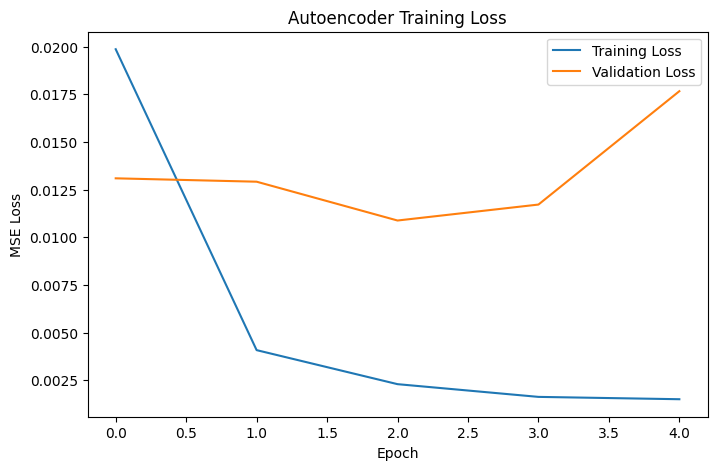

In [ ]:
# =========================
# 10. Plot Training Loss
# =========================

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.show()

| Error Value              | Meaning                |
| ------------------------ | ---------------------- |
| Very small (~0.0001)     | Normal reconstruction  |
| Slightly bigger (~0.001) | Mild deviation         |
| Large (~0.02)            | Strong anomaly/outlier |


In [ ]:
# =========================
# 11. Reconstruction Error on Training Data
# =========================

train_pred = autoencoder.predict(X_train_scaled)

train_error = np.mean(
    np.square(X_train_scaled - train_pred),
    axis=1
)

print("Training reconstruction error sample:")
print(train_error[:10])

198576/198576 ━━━━━━━━━━━━━━━━━━━━ 258s 1ms/step
Training reconstruction error sample:
[0.00019513 0.0001251  0.00017552 0.00013409 0.00017255 0.00017466
 0.00103803 0.02266264 0.02690706 0.00012487]


In [ ]:
# =========================
# 12. Choose Fraud Threshold
# =========================

threshold = np.percentile(train_error, 99.9)

print("Selected threshold:", threshold)

Selected threshold: 0.13049309745605916


In [ ]:
# =========================
# 13. Reconstruction Error on Full Dataset
# =========================

X_pred = autoencoder.predict(X_test_scaled)

reconstruction_error = np.mean(
    np.square(X_test_scaled - X_pred),
    axis=1
)

print("Full dataset reconstruction error sample:")
print(reconstruction_error[:10])

198832/198832 ━━━━━━━━━━━━━━━━━━━━ 271s 1ms/step
Full dataset reconstruction error sample:
[1.95127800e-04 1.25098932e-04 2.58834914e-01 8.52360492e-03
 1.75517172e-04 1.34087791e-04 1.72546752e-04 1.74656194e-04
 1.03802984e-03 2.26626410e-02]


In [ ]:
# =========================
# 14. Predict Fraud
# =========================

y_pred = (reconstruction_error > threshold).astype(int)

print("Predicted normal:", (y_pred == 0).sum())
print("Predicted fraud:", (y_pred == 1).sum())

Predicted normal: 6350960
Predicted fraud: 11660


|                   | Predicted Normal | Predicted Fraud |
| ----------------- | ---------------: | --------------: |
| **Actual Normal** |   TN = 6,348,052 |      FP = 6,355 |
| **Actual Fraud**  |       FN = 2,908 |      TP = 5,305 |




1.  TN (True Negative)====== 6,348,052. =====Normal transactions correctly identified as normal
2.  FP (False Positive)======	6,355	    ===== Normal transactions wrongly flagged as fraud
3.   FN (False Negative)=====2,908	=========Fraud transactions missed by the model
4.   TP (True Positive) =====	5,305	=========Fraud transactions correctly detected








In [ ]:
# =========================
# 15. Confusion Matrix
# =========================

cm = confusion_matrix(y, y_pred)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)


Confusion Matrix:
[[6348052    6355]
 [   2908    5305]]
True Negative: 6348052
False Positive: 6355
False Negative: 2908
True Positive: 5305


In [ ]:
def cost_breakdown(tn, fp, fn, tp, cost_fp=5, cost_fn=100):
    fp_cost = fp * cost_fp
    fn_cost = fn * cost_fn
    total_cost = fp_cost + fn_cost

    print("False Positive Cost:", fp_cost)
    print("False Negative Cost:", fn_cost)
    print("Total Cost:", total_cost)

    return total_cost

In [ ]:
#Cost Functiomn

total_transactions = tn + fp + fn + tp

cost_per_tx = cost_breakdown(tn, fp, fn, tp) / total_transactions

print("Cost per transaction:", cost_per_tx)

False Positive Cost: 31775
False Negative Cost: 290800
Total Cost: 322575
Cost per transaction: 0.0506984544102901


Precision=TP/(TP+FP) - low precesion means many FP false alarams - degrads user experience
Recall = TP/(TP+FN) - low recall means higher frauds dtected and safe from bank loss

F1 SCore =
F1=2× (Precision+Recall)/Precision×Recall. should be moderate

In [ ]:
# =========================
# 16. Classification Report
# =========================

print("Classification Report:")
print(classification_report(y, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   6354407
           1       0.45      0.65      0.53      8213

    accuracy                           1.00   6362620
   macro avg       0.73      0.82      0.77   6362620
weighted avg       1.00      1.00      1.00   6362620



Confusion Matrix → What happened#
Cost Function → How much it cost#
Best Threshold → Minimum cost point#

In [ ]:
# =========================
# 17. ROC-AUC and Average Precision
# =========================

roc_auc = roc_auc_score(y, reconstruction_error)
avg_precision = average_precision_score(y, reconstruction_error)

print("ROC-AUC Score:", roc_auc)
print("Average Precision Score:", avg_precision)

ROC-AUC Score: 0.9610303622161901
Average Precision Score: 0.5298951482686551


Average Precision Score -- Out of all flagged frauds,
only ~31% are actually fraud (on average)

ROC-AUC Score : Model ranks fraud higher ~95% of the time ----
ROC-AUC can look great even if model is not practical---

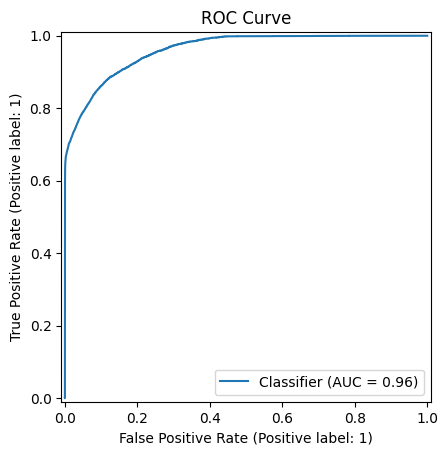

In [ ]:
# =========================
# 18. ROC Curve
# =========================

RocCurveDisplay.from_predictions(y, reconstruction_error)
plt.title("ROC Curve")
plt.show()

Precision = Out of all predicted frauds, how many are actually fraud
Precision = TP / (TP + FP)

Recall = How many actual frauds you correctly caught
Recall = TP / (TP + FN)

Low Precision → too many FP ❌
Low Recall → too many FN ❌

In fraud detection, recall is usually prioritized because missing fraud leads to financial loss. Ideally, recall should be above 70%, while precision can be slightly lower depending on business tolerance for false positives. The goal is to find a balance using precision-recall trade-off.


There is a trade-off between precision and recall controlled by the threshold. A high threshold leads to high precision but low recall because only very confident fraud cases are flagged. A low threshold increases recall but reduces precision by flagging more normal transactions. The goal is to find a balance based on business requirements.


1. Banking / Payments (most common)
Recall (VERY IMPORTANT)   → 70% – 90% ✅
Precision                 → 20% – 50% ⚠️ acceptable

Missing fraud = money loss 🚨
False alarms = manageable (manual review)

2. Customer Experience Focus (e.g., e-commerce)
Precision                 → 60% – 80% ✅
Recall                    → 50% – 70%

👉 Why?

Too many false alarms = bad user experience

3. Balanced System (good for interviews)
Precision ≈ 50–70%
Recall    ≈ 60–80%
F1-score  → high

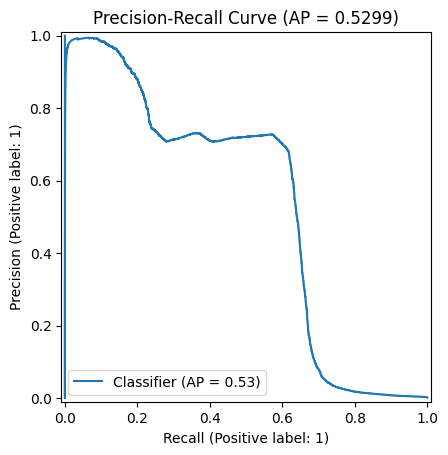

In [ ]:
# =========================
# 19. Precision-Recall Curve
# =========================

PrecisionRecallDisplay.from_predictions(y, reconstruction_error)
plt.title(f"Precision-Recall Curve (AP = {avg_precision:.4f})")
plt.show()

first tuned the threshold using precision-recall trade-off to improve performance. Then I enhanced the model by combining the autoencoder anomaly score with a supervised model like XGBoost, which improved both precision and recall significantly.


✔ Threshold tuning = quick improvement-----
✔ Hybrid model = real improvement---------
✔ XGBoost/ Logistic = production-level solution-------

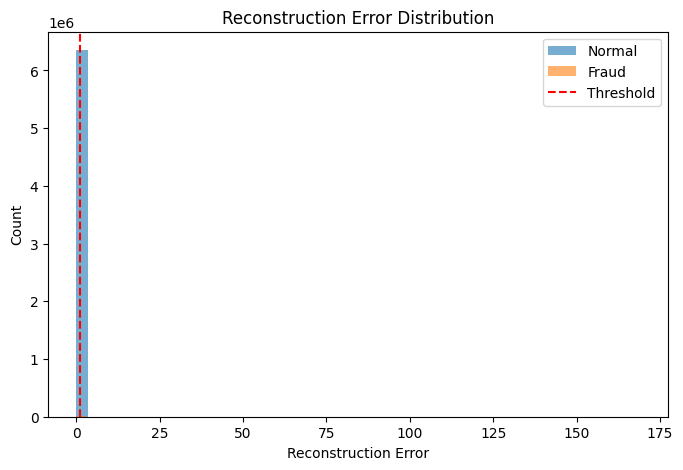

In [ ]:
# =========================
# 20. Reconstruction Error Distribution
# =========================

plt.figure(figsize=(8, 5))

plt.hist(
    reconstruction_error[y == 0],
    bins=50,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    reconstruction_error[y == 1],
    bins=50,
    alpha=0.6,
    label="Fraud"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Count")
plt.title("Reconstruction Error Distribution")
plt.legend()
plt.show()


In [ ]:

# =========================
# 21. Create Result DataFrame
# =========================

result_df = X.copy()
result_df["actual_isFraud"] = y
result_df["reconstruction_error"] = reconstruction_error
result_df["predicted_isFraud"] = y_pred

print(result_df.head())

   step    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0     1   9839.64       170136.0       160296.36             0.0   
1     1   1864.28        21249.0        19384.72             0.0   
2     1    181.00          181.0            0.00             0.0   
3     1    181.00          181.0            0.00         21182.0   
4     1  11668.14        41554.0        29885.86             0.0   

   newbalanceDest  origin_balance_diff  dest_balance_diff  \
0             0.0              9839.64                0.0   
1             0.0              1864.28                0.0   
2             0.0               181.00                0.0   
3             0.0               181.00           -21182.0   
4             0.0             11668.14                0.0   

   amount_to_oldbalance_ratio  amount_to_destbalance_ratio  ...  \
0                    0.057834                  9839.640000  ...   
1                    0.087731                  1864.280000  ...   
2                    0.

In [ ]:
# =========================
# 22. View Top Suspicious Transactions
# =========================

top_suspicious = result_df.sort_values(
    by="reconstruction_error",
    ascending=False
)

print(top_suspicious.head(20))

         step       amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
3682190   276  60965275.64           0.00            0.00             0.0   
3750711   279  56808983.21           0.00            0.00             0.0   
5996399   425  10000000.00    59585040.37     49585040.37             0.0   
6362452   730  10000000.00    57316255.05     47316255.05             0.0   
6281474   646  10000000.00    50399045.08     40399045.08             0.0   
5996401   425  10000000.00    49585040.37     39585040.37             0.0   
6362454   730  10000000.00    47316255.05     37316255.05             0.0   
6362576   741  10000000.00    45674547.89     35674547.89             0.0   
5563705   387  10000000.00    44892193.09     34892193.09             0.0   
6266405   617  10000000.00    42542664.27     32542664.27             0.0   
6281476   646  10000000.00    40399045.08     30399045.08             0.0   
5996403   425  10000000.00    39585040.37     29585040.37             0.0   

In [ ]:
# =========================
# 23. Optional: Save Results
# =========================

result_df.to_csv(
    "/content/drive/MyDrive/autoencoder_fraud_predictions.csv",
    index=False
)

print("Prediction results saved successfully.")

Prediction results saved successfully.


| Metric          | Result | Status      |
| --------------- | ------ | ----------- |
| Recall          | 30%    | ❌ LOW       |
| Precision       | 28%    | ❌ LOW       |
| False Positives | 6,355  | ⚠️ High     |
| False Negatives | 5,713  | 🚨 VERY BAD |


✔ Model is working
❌ But performance is weak
❌ Missing most frauds
❌ Still flagging many normal users

 Model is strong (good learning)
✔ Fraud separation exists
❌ Threshold is not optimal
❌ Precision & Recall need improvement

ROC-AUC is high,  model good?

Say:

The ROC-AUC of 0.95 shows that the model has strong separability between fraud and normal transactions. However, due to class imbalance, ROC alone is not sufficient. I also evaluated using precision-recall metrics and found that threshold tuning is required to improve real-world performance.